# P59: lag-0 tooth out of the remaining comb gates
Regenerates every README figure from `data/` (no pipeline runs). Heavy steps: `p59lib.py` (sweeps), `run_scorecards.sh`, `examples.py`.

In [1]:
import sys, json, pickle
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
sys.path.insert(0, str(Path.cwd()))
import importlib.util
spec = importlib.util.spec_from_file_location('p59_figures', Path.cwd() / 'figures.py')
F = importlib.util.module_from_spec(spec); spec.loader.exec_module(F)
chosen = json.load(open(F.DATA / 'chosen.json'))
{k: chosen[k] for k in ('chosen', 'modes_agree')}

{'chosen': {'mp': 2, 'fp': 0.6, 'snr': 1.06}, 'modes_agree': False}

## Headline: official scorecards vs `_v9` (old = `_v9` default l0x, new = l0x2 rule pick, alt = l0x2b)

In [2]:
pd.read_csv(F.DATA / 'summary.csv').round(3)

,set,mode,run,n,success,wrong,alias,none,precision,gained,lost,new_wrong,fixed_wrong
0,dev_medium_clean,fullyear,old,874,0.270,0.019,0.008,0.703,0.908,NaN,NaN,NaN,NaN
1,dev_medium_clean,fullyear,new,874,0.283,0.027,0.006,0.684,0.895,23.0,12.0,11.0,4.0
2,dev_medium_clean,fullyear,alt,874,0.273,0.023,0.005,0.699,0.909,14.0,11.0,7.0,4.0
3,dev_medium_clean,assigned,old,874,0.154,0.030,0.005,0.811,0.818,NaN,NaN,NaN,NaN
4,dev_medium_clean,assigned,new,874,0.175,0.049,0.009,0.767,0.750,23.0,5.0,18.0,1.0
5,dev_medium_clean,assigned,alt,874,0.160,0.038,0.005,0.797,0.791,8.0,3.0,7.0,0.0
6,dev_medium_b_clean,fullyear,old,1000,0.272,0.032,0.009,0.687,0.869,NaN,NaN,NaN,NaN
7,dev_medium_b_clean,fullyear,new,1000,0.284,0.032,0.011,0.673,0.869,20.0,8.0,4.0,4.0
8,dev_medium_b_clean,fullyear,alt,1000,0.274,0.032,0.009,0.685,0.870,14.0,12.0,3.0,3.0
9,dev_medium_b_clean,assigned,old,1000,0.168,0.019,0.002,0.811,0.889,NaN,NaN,NaN,NaN


## Purity–completeness on B: every combination, both definitions

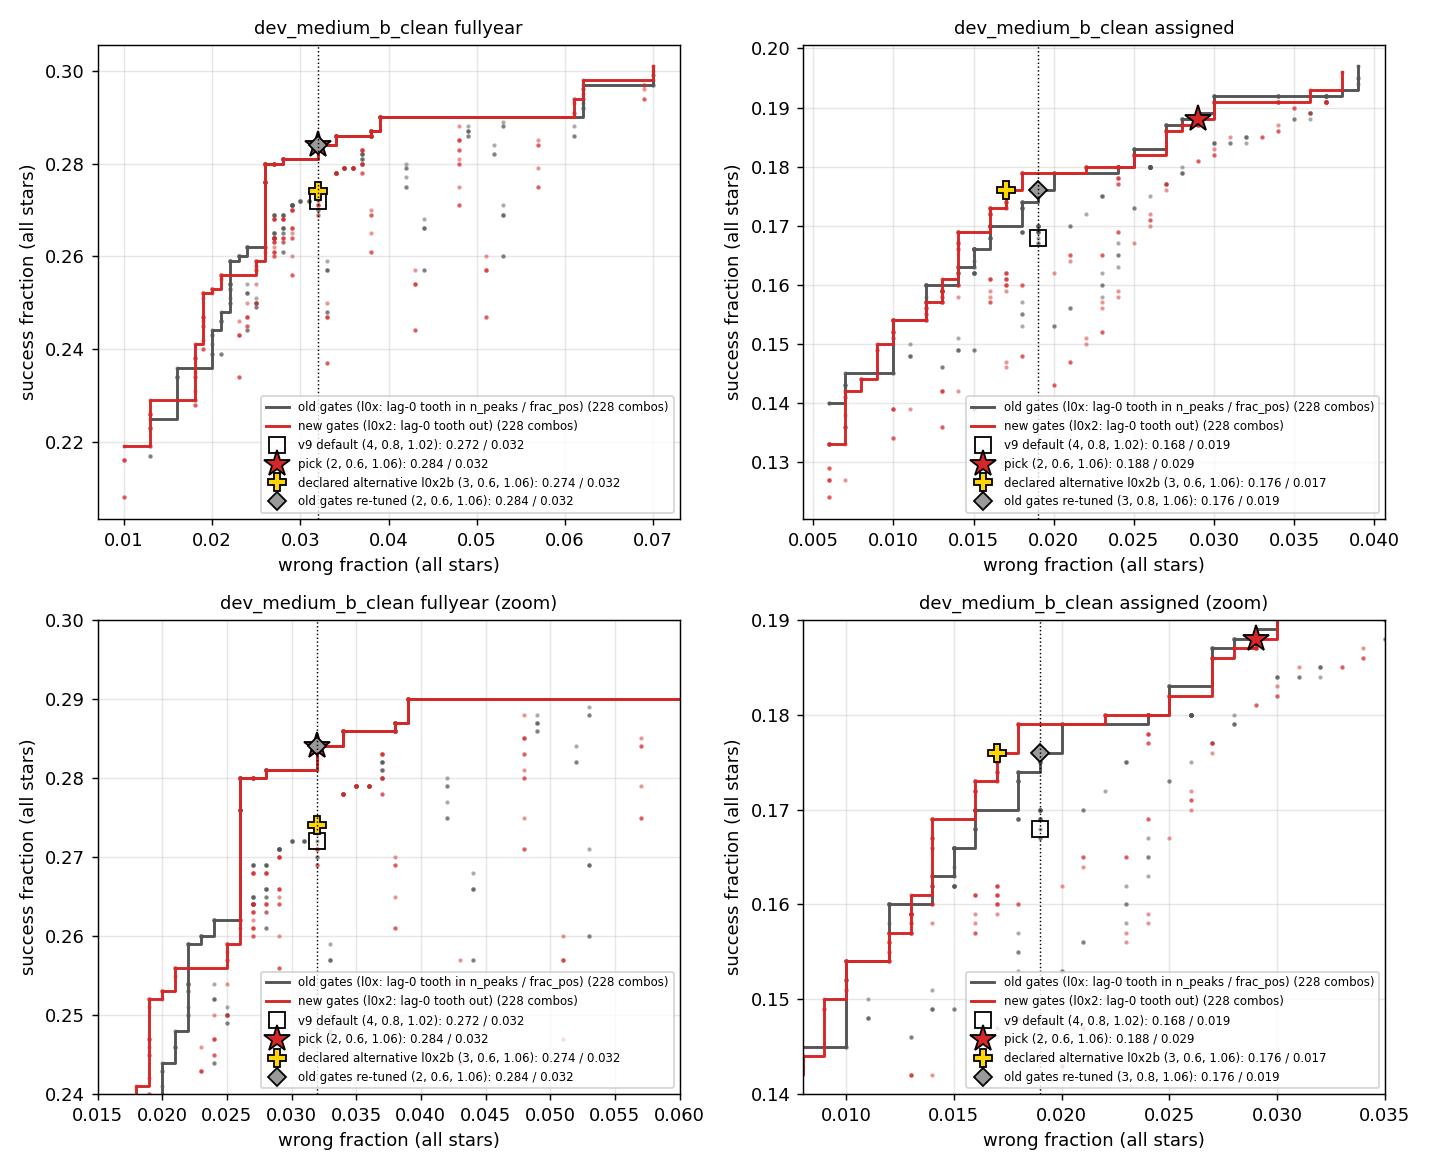

In [3]:
F.fig_frontier(chosen); display(Image(F.FIG / 'fig_frontier.png'))

## Threshold maps, B full-year, new definition

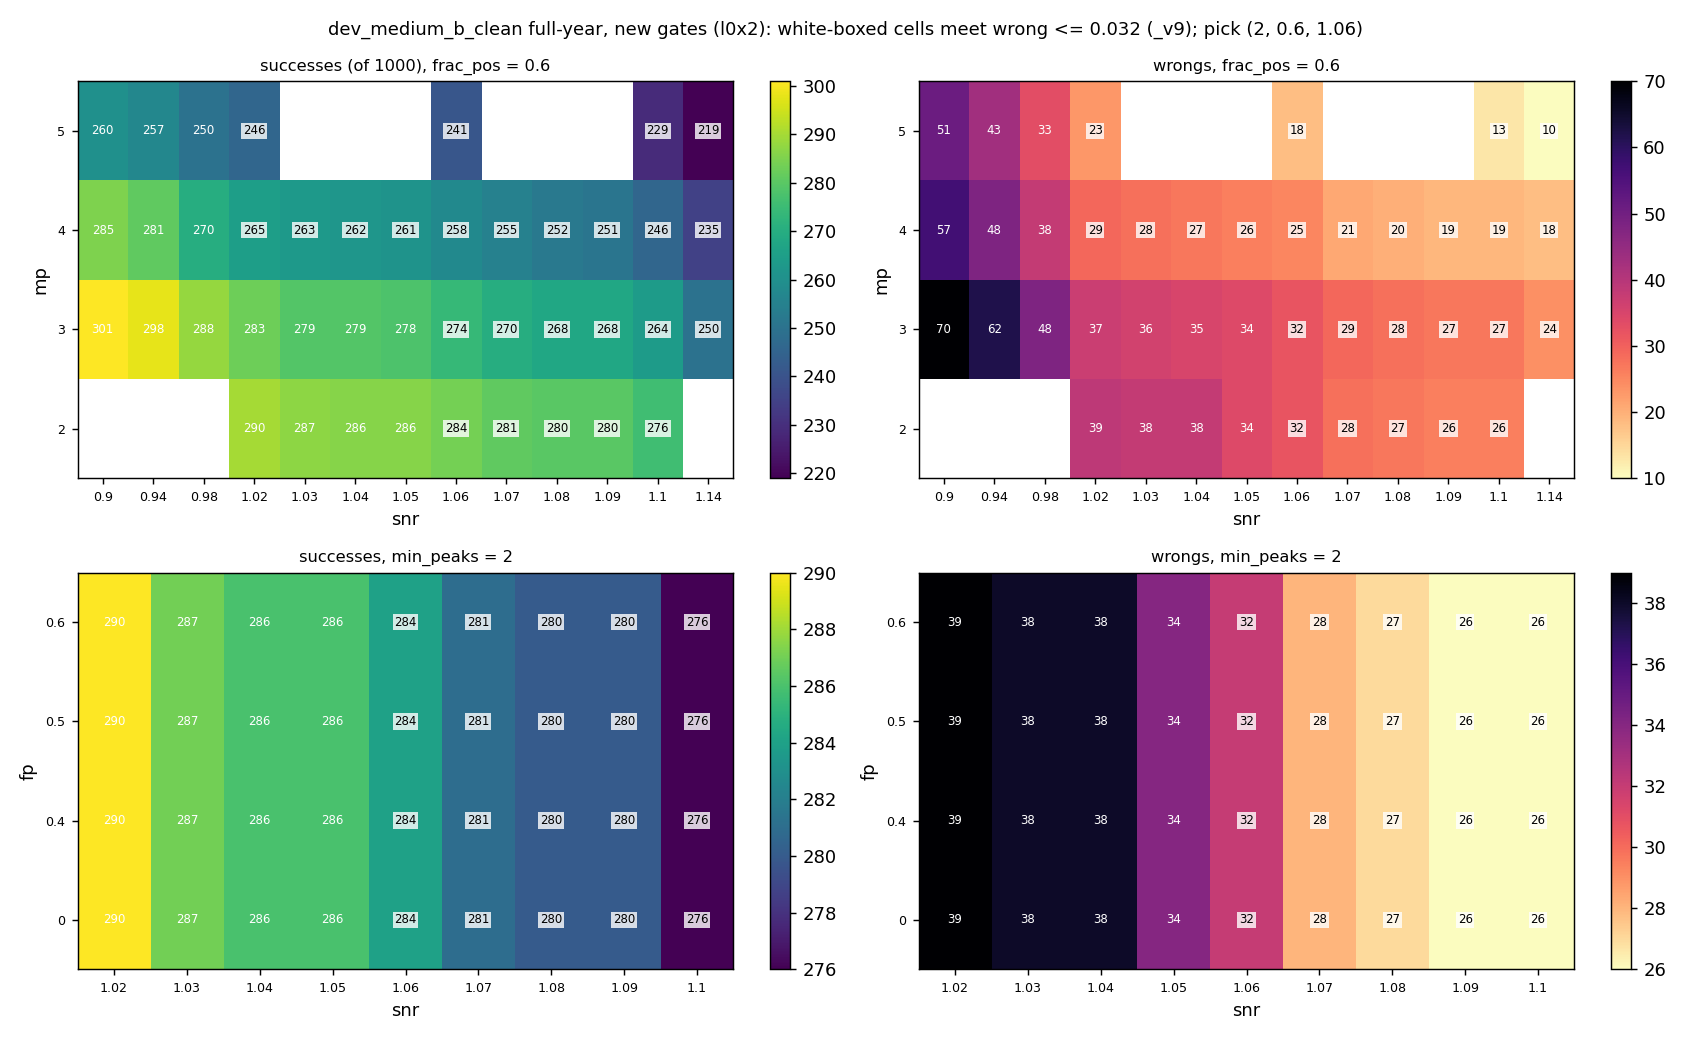

In [4]:
F.fig_map(chosen); display(Image(F.FIG / 'fig_map.png'))

## Per-bin outcomes, `_v9` vs l0x2 (68% Wilson intervals)

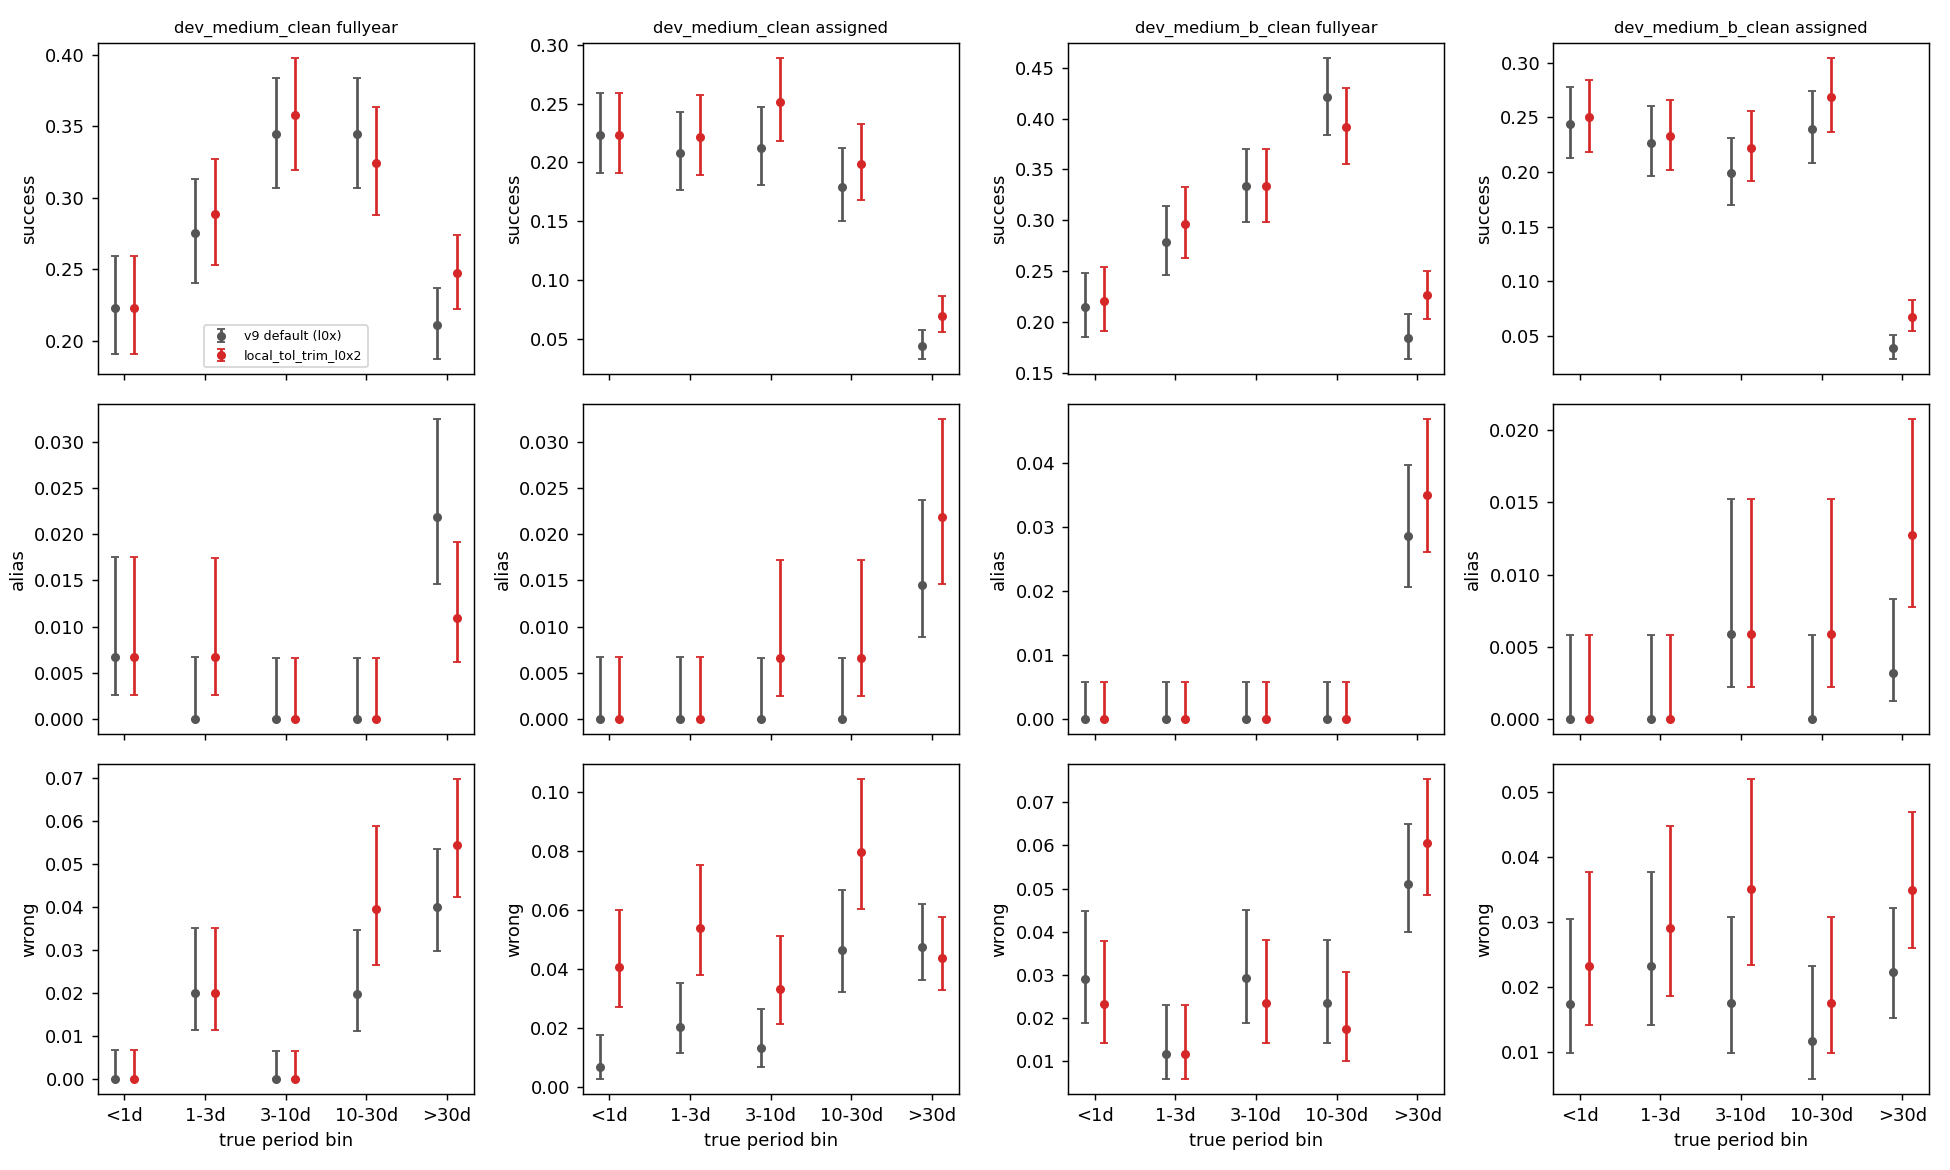

In [5]:
F.fig_bins(); display(Image(F.FIG / 'fig_bins.png'))

## Gate-failure breakdown

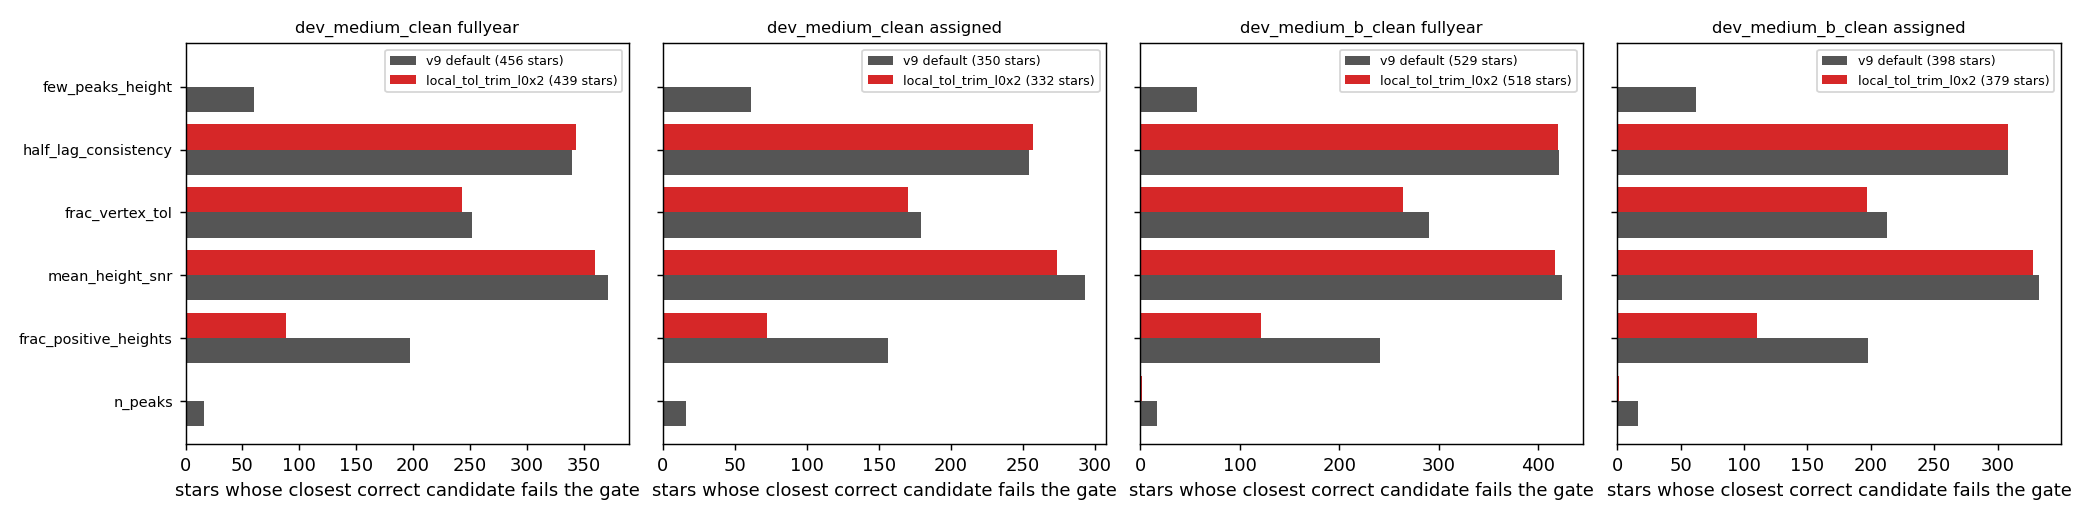

In [6]:
F.fig_gates(); display(Image(F.FIG / 'fig_gates.png'))

## Example combs (judging set, diagnosis only)

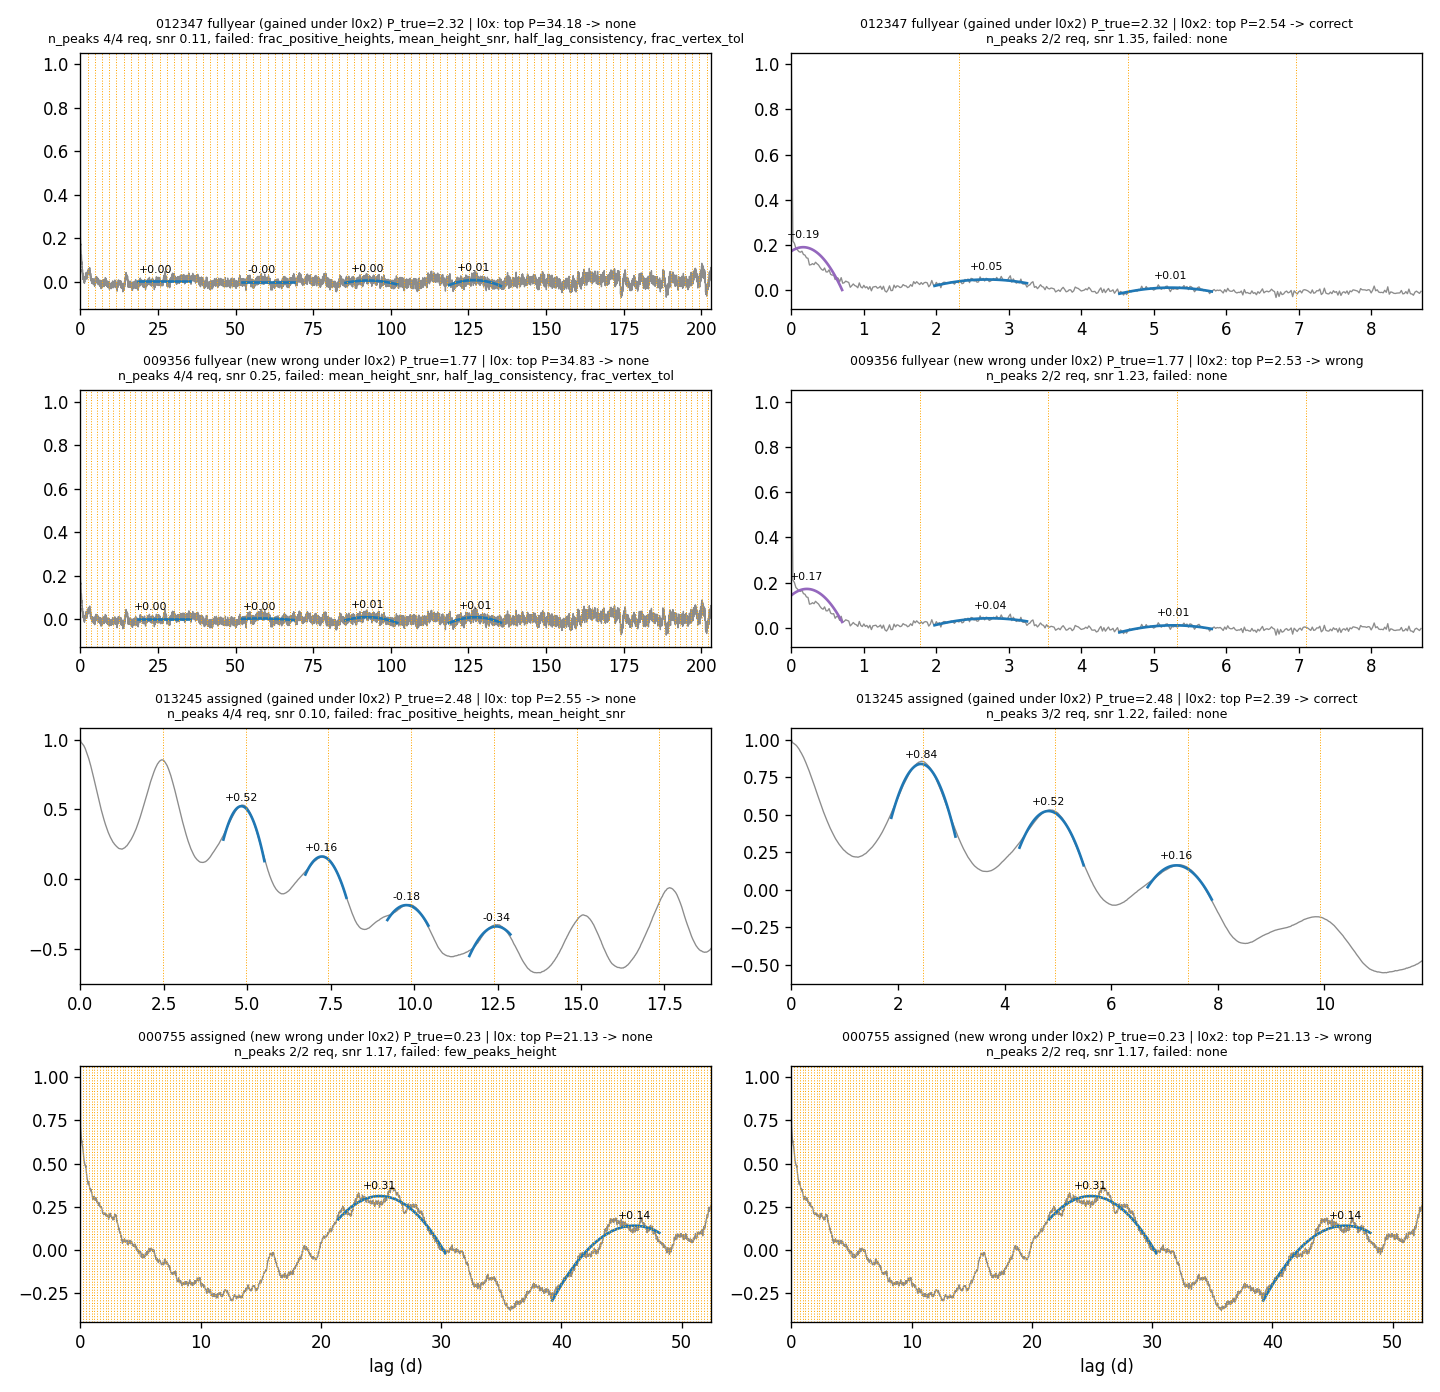

In [7]:
import examples as E
recs = pickle.load(open(F.DATA / 'examples.pkl', 'rb'))
E.plot(recs, F.FIG / 'fig_examples.png'); display(Image(F.FIG / 'fig_examples.png'))